# Training-only selection and final testing

Protocol fixed in reports/AUDIT.md before new results. For each target: stratified 80/20 split (seed 2026); training-only 5-fold CV repeated twice compares RF/HGB × statistics/statistics+FFT. Different targets have different test cycle IDs. Select by mean macro-F1; deterministic ties favor earlier candidates. Fold SD describes variation, not an independent-sample confidence interval.

Training-only diagnostics: feature and grouped sensor permutations on one validation fold (five repeats); paired three-fold RF ablation of every sensor and family; ordered expanding-window sensitivity with a ten-training-row gap. These diagnostics do not change the selected model. Ordered rows are a proxy for acquisition sequence, not verified timestamps or independent assets.

Only then refit the selected candidate and predict the test once. Bootstrap and stability diagnostics reuse these predictions. This public dataset was previously explored: the test is untouched during this revision's selection, not independent external validation.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import *
FIG = ROOT / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
profile = load_profile()
from src.evaluation import run_experiment
from src.reporting import plot_results, result_table
X = pd.read_pickle(ROOT / 'data' / 'features.pkl')
assert len(X) == len(profile)


In [2]:
results = run_experiment(X, profile, ROOT / 'reports')
display(result_table(results))


Target: cooler


rf statistics 0.99859


hgb statistics 0.99859


rf statistics_fft 0.99859


hgb statistics_fft 0.99859


...

rf statistics_fft 0.99035


hgb statistics_fft 0.98981


Training diagnostics: rf statistics_fft


Final test: 0.9914553998447327


,target,model,features,cv_mean,test_macro_f1,test_ci95,test_accuracy
0,cooler,rf,statistics,0.998588,0.997725,"[0.9931737433746869, 1.0]",0.997732
1,valve,rf,statistics,0.989184,0.965739,"[0.9440803049943381, 0.9839205683648735]",0.975057
2,pump,rf,statistics,0.993916,0.994256,"[0.9841018620895418, 1.0]",0.995465
3,accumulator,rf,statistics_fft,0.990354,0.991455,"[0.9807596044948925, 1.0]",0.993197


cooler training-only candidate comparison


,model,features,n_features,fold_macro_f1,mean,std
0,rf,statistics,187,"[0.9943498767028179, 1.0, 1.0, 0.9971750905227...",0.998588,0.001998
1,hgb,statistics,187,"[0.9971750905227879, 1.0, 0.9971509451191672, ...",0.998585,0.001491
2,rf,statistics_fft,229,"[0.9943498767028179, 1.0, 1.0, 0.9971750905227...",0.998588,0.001998
3,hgb,statistics_fft,229,"[0.9971750905227879, 1.0, 0.9971509451191672, ...",0.998585,0.001491


Final test stable=0 / possibly transient=1, fixed label universe


,n,accuracy,macro_f1,macro_f1_ci95,labels,class_support,per_class_recall,confusion_matrix
0,287,1.0,1.0,"[1.0, 1.0]","[3, 20, 100]","[92, 93, 102]","[1.0, 1.0, 1.0]","[[92, 0, 0], [0, 93, 0], [0, 0, 102]]"
1,154,0.993506,0.993827,"[0.9814671814671815, 1.0]","[3, 20, 100]","[54, 54, 46]","[1.0, 0.9814814814814815, 1.0]","[[54, 0, 0], [1, 53, 0], [0, 0, 46]]"


Training-only ordered sensitivity


...

,model,features,n_features,fold_macro_f1,mean,std
0,rf,statistics,187,"[0.9872747229240233, 1.0, 0.9722049627726892, ...",0.984210,0.009772
1,hgb,statistics,187,"[0.9934544264441172, 0.9880208735542004, 0.983...",0.988478,0.006399
2,rf,statistics_fft,229,"[0.989911440696781, 0.9941399152029073, 0.9902...",0.990354,0.004687
3,hgb,statistics_fft,229,"[0.9869562607423392, 0.9898649082789303, 0.973...",0.989811,0.007016


Final test stable=0 / possibly transient=1, fixed label universe


,n,accuracy,macro_f1,macro_f1_ci95,labels,class_support,per_class_recall,confusion_matrix
0,287,0.993031,0.993138,"[0.9828084294527247, 1.0]","[90, 100, 115, 130]","[78, 69, 72, 68]","[0.9871794871794872, 0.9855072463768116, 1.0, ...","[[77, 0, 1, 0], [0, 68, 1, 0], [0, 0, 72, 0], ..."
1,154,0.993506,0.973389,"[0.9210526315789473, 1.0]","[90, 100, 115, 130]","[83, 11, 8, 52]","[1.0, 0.9090909090909091, 1.0, 1.0]","[[83, 0, 0, 0], [0, 10, 1, 0], [0, 0, 8, 0], [..."


Training-only ordered sensitivity


,n_train,n_validation,train_cycle_range,validation_cycle_range,missing_training_classes,macro_f1
0,431,441,"[0, 549]","[561, 1099]",[90],0.239876
1,872,441,"[0, 1088]","[1100, 1662]",[],0.108033
2,1313,441,"[0, 1651]","[1663, 2204]",[],0.136616


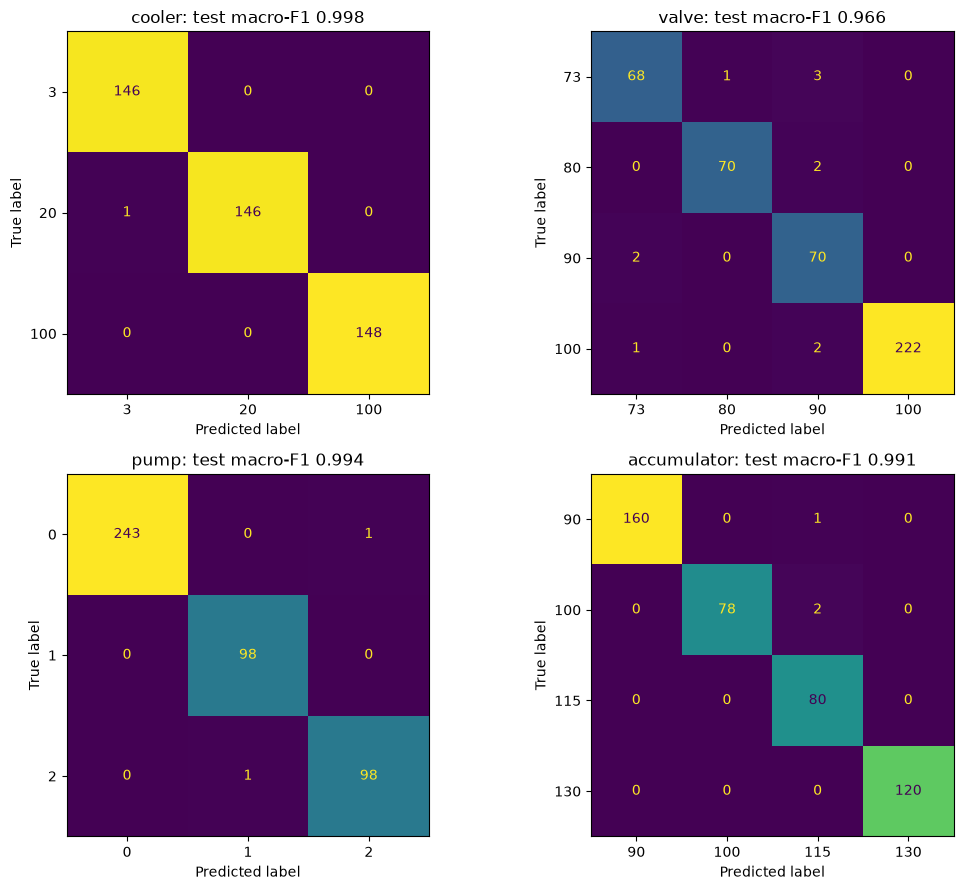

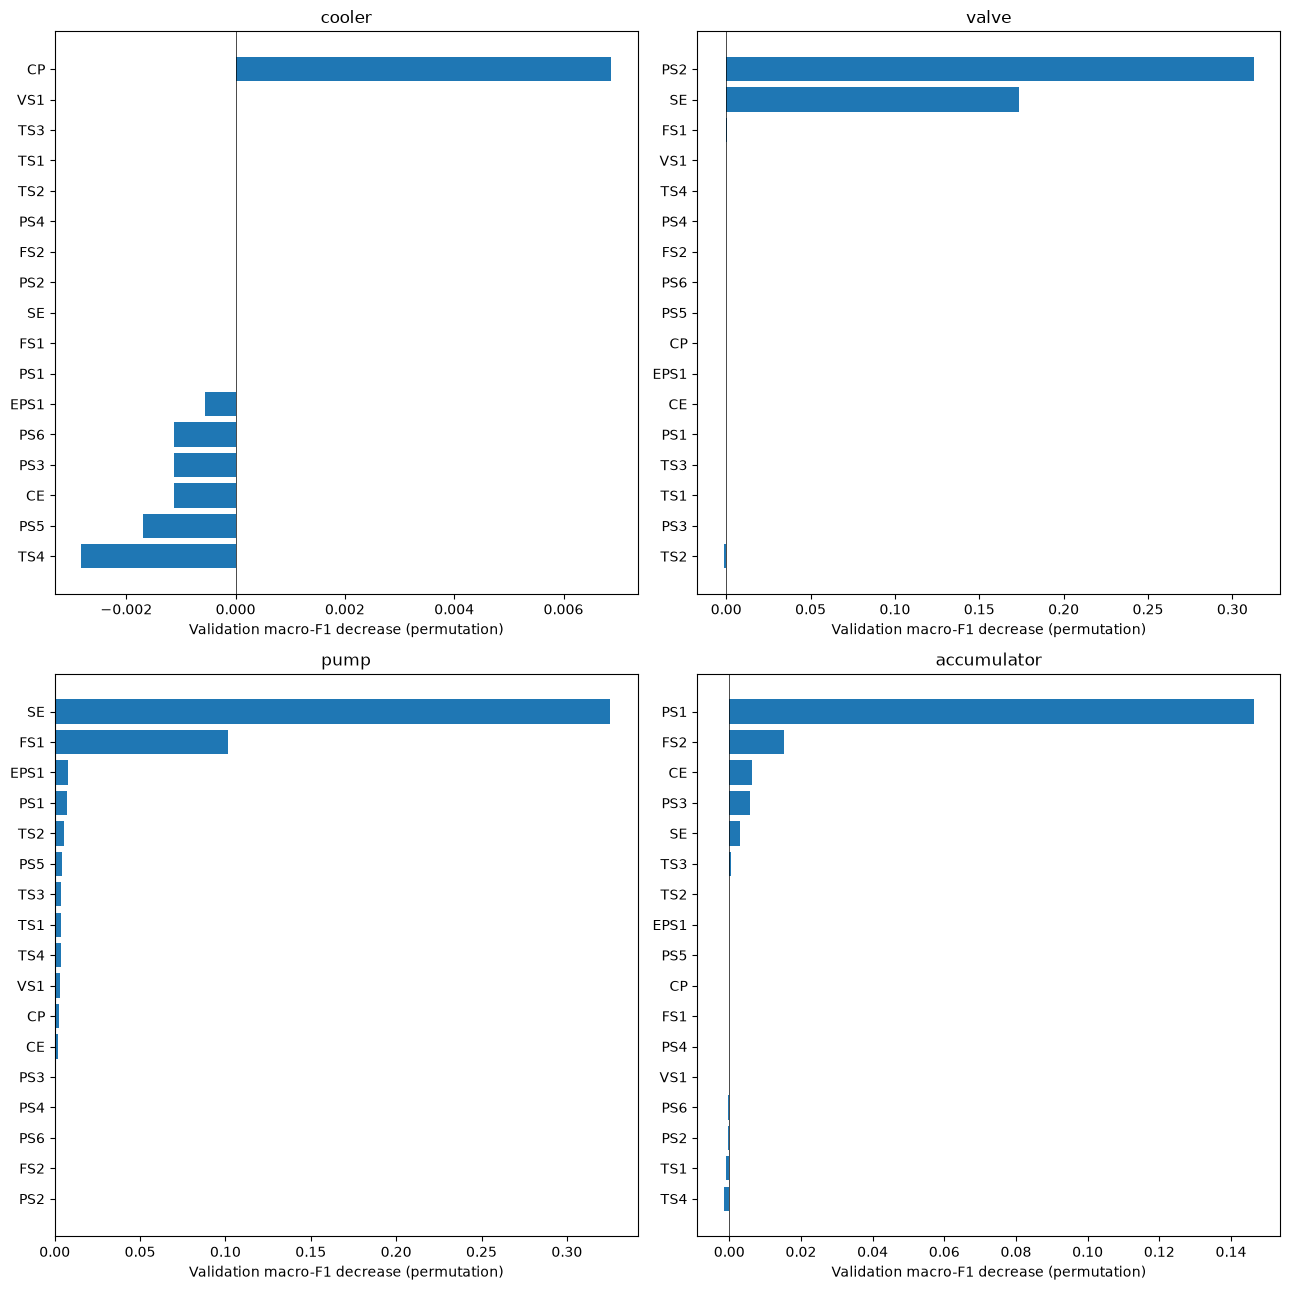

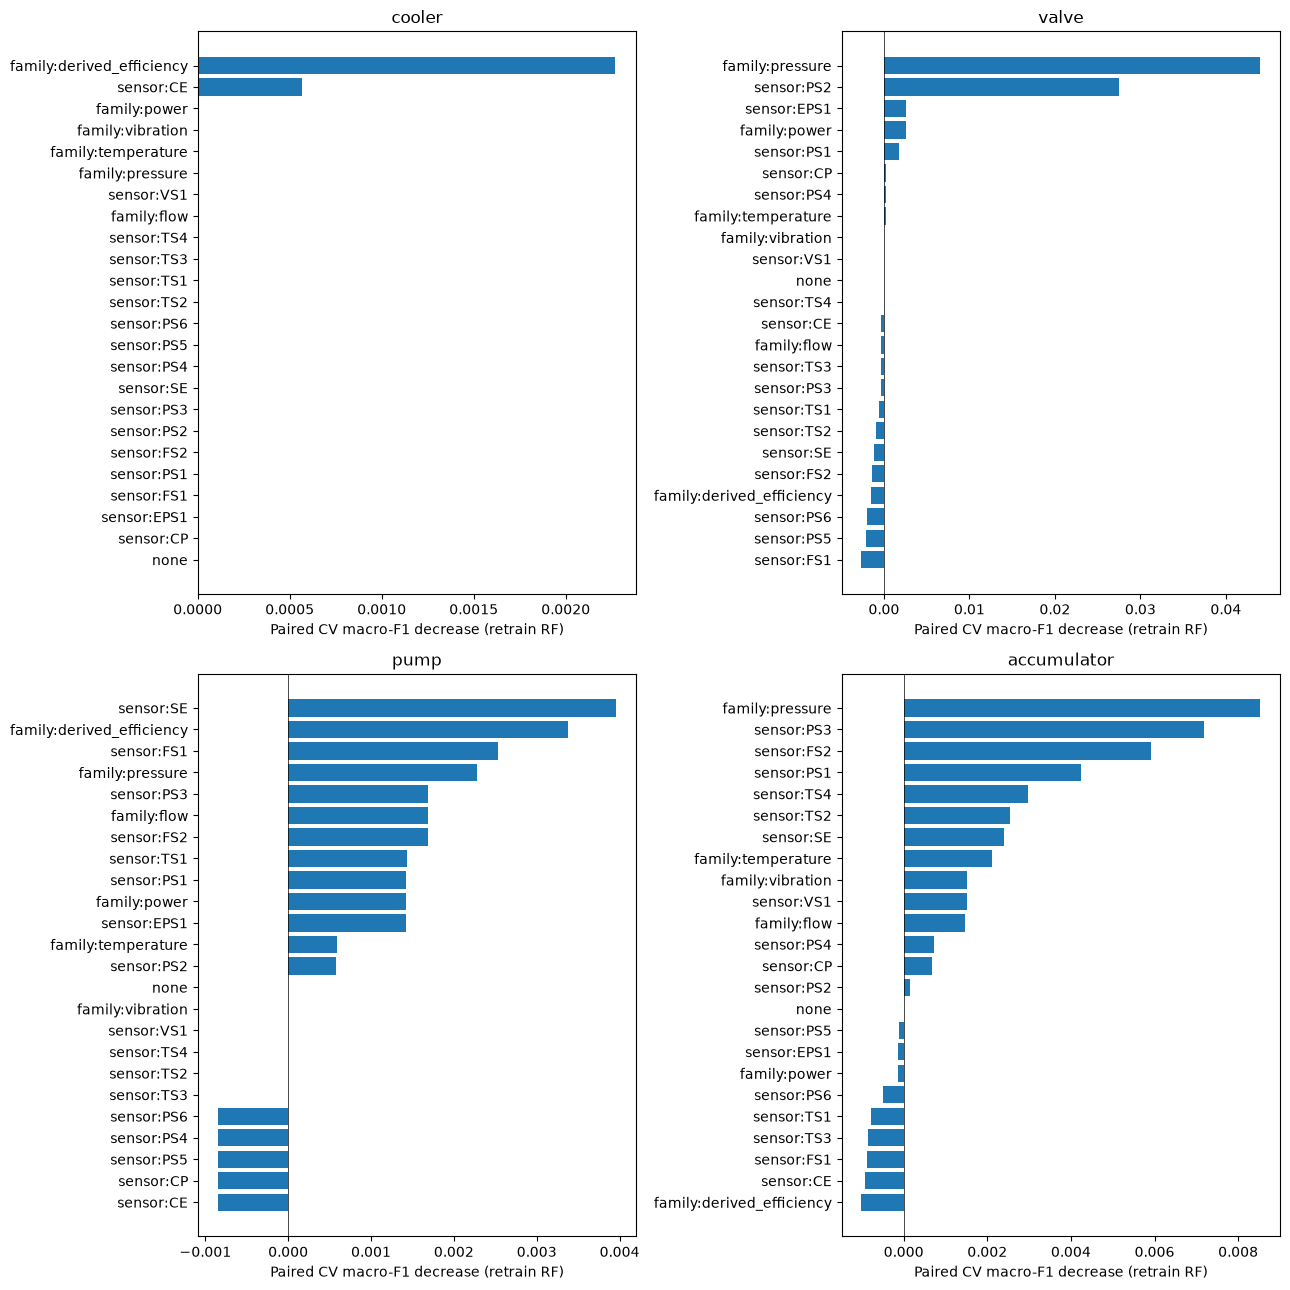

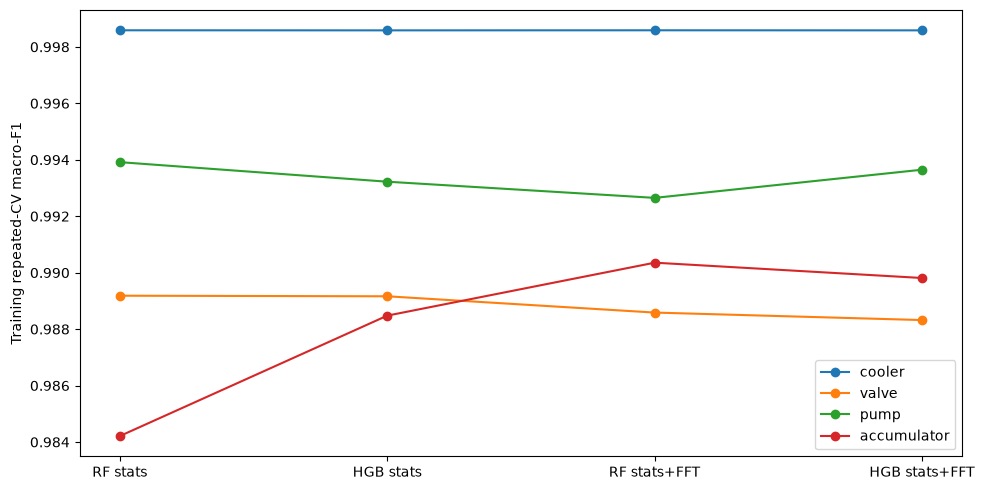

In [3]:
for target, result in results['targets'].items():
    print(target, 'training-only candidate comparison')
    display(pd.DataFrame(result['cv']))
    print('Final test stable=0 / possibly transient=1, fixed label universe')
    display(pd.DataFrame(result['stability']).T)
    print('Training-only ordered sensitivity')
    display(pd.DataFrame(result['ordered_sensitivity']))
plot_results(results, FIG)


## Interpretation and limits

Permutation measures sensitivity of a fitted model to disrupted inputs; retrained ablation measures the diagnostic RF's ability to compensate with remaining features. Correlation can conceal individual importance; permutation can create unrealistic combinations. Five permutation repeats and three ablation folds are exploratory. CE/CP are virtual channels and SE is derived efficiency: removing a physical sensor while retaining derived signals does not simulate a physically feasible retrofit.

The 95% intervals use 2,000 class-stratified bootstrap resamples of fixed predictions. They condition on training, class counts and independent cycles, omit selection uncertainty, and may collapse to [1,1] for perfect predictions. They are not field-performance bounds. Random cycles can share operating regimes. Ordered sensitivity may encounter unseen classes and confounds class shift with ordering.

These test-rig classification results do not establish field reliability, remaining useful life, probability calibration, economic benefit, or maintenance recommendations. Instrumentation purchasing requires physical dependency mapping, sensor cost/reliability evidence and prospective validation on new assets. See PROJECT_GUIDE.md for verified results and remaining work.